In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 
from pathlib import Path

In [4]:
# Cell 2 : load the dataset from processed
df = pd.read_parquet("../data/processed/ca1_long.parquet")
print("shape:", df.shape)
print("memory (MB):", round(df.memory_usage(deep=True).sum() / 1e6, 1))
print("price missing:", df["sell_price"].isna().sum())
display(df.head())

shape: (5918109, 19)
memory (MB): 207.7
price missing: 1129842


,id,item_id,dept_id,cat_id,store_id,state_id,sales,d_num,date,wm_yr_wk,wday,month,year,event_name_1,event_type_1,event_name_2,event_type_2,snap,sell_price
0,FOODS_1_001_CA_1_evaluation,FOODS_1_001,FOODS_1,FOODS,CA_1,CA,3,1,2011-01-29,11101,1,1,2011,NaN,NaN,NaN,NaN,0,2.0
1,FOODS_1_001_CA_1_evaluation,FOODS_1_001,FOODS_1,FOODS,CA_1,CA,0,2,2011-01-30,11101,2,1,2011,NaN,NaN,NaN,NaN,0,2.0
2,FOODS_1_001_CA_1_evaluation,FOODS_1_001,FOODS_1,FOODS,CA_1,CA,0,3,2011-01-31,11101,3,1,2011,NaN,NaN,NaN,NaN,0,2.0
3,FOODS_1_001_CA_1_evaluation,FOODS_1_001,FOODS_1,FOODS,CA_1,CA,1,4,2011-02-01,11101,4,2,2011,NaN,NaN,NaN,NaN,1,2.0
4,FOODS_1_001_CA_1_evaluation,FOODS_1_001,FOODS_1,FOODS,CA_1,CA,4,5,2011-02-02,11101,5,2,2011,NaN,NaN,NaN,NaN,1,2.0


### **Univariate Analysis**

days: 1941
average units per day: 4035

lowest 5 days:


date
2011-12-25    0
2012-12-25    0
2013-12-25    0
2014-12-25    0
2015-12-25    0
Name: units, dtype: int16

highest 5 days:


date
2013-08-25    6948
2016-03-06    6829
2015-08-02    6768
2016-05-15    6707
2013-09-08    6703
Name: units, dtype: int16

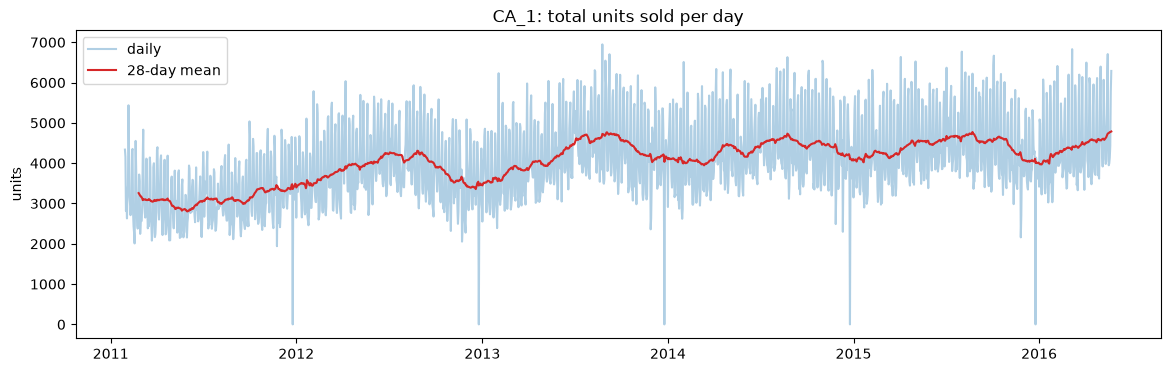

In [5]:
# Cell 3: Total daily sales over time
daily = df.groupby("date", observed=True)["sales"].sum().rename("units").to_frame()
daily["roll28"] = daily["units"].rolling(28).mean()

print("days:", len(daily))
print("average units per day:", round(daily["units"].mean()))
print("\nlowest 5 days:")
display(daily["units"].nsmallest(5))
print("highest 5 days:")
display(daily["units"].nlargest(5))

fig, ax = plt.subplots(figsize = (14, 4))
ax.plot(daily.index, daily["units"], alpha = 0.35, label = "daily")
ax.plot(daily.index, daily["roll28"], color = "C3", label = "28-day mean")
ax.set_title("CA_1: total units sold per day")
ax.set_ylabel("units")
ax.legend()
plt.show()

### Analysis of above chart

- Trend: the red line climbs from about 3,000 units/day in 2011 to about 4,700 in 2013-2014, then stays roughly flat between 4,000 and 4,800. The series is not stationary, so a model must not assume a constant level.
- Christmas closures: the five lowest days are all 25 December (2011 to 2015), with exactly 0 units. The store is closed, so this is not “no demand”. The highest days (all Sundays by the calendar, and we’ll confirm in Cell 5) are 6,700 to 6,950 units.
- Weekly pattern: the blue band is very wide, with daily swings of about 2,000 units. That is a strong weekly cycle, which we measure in the bivariate step.
- Yearly pattern: the red line seems to dip around the turn of each year and peak in late summer, but that is only from eyeballing. We confirm it with monthly averages.
Average: 4,035 units/day, which matches 7,832,248 units / 1,941 days.

## What this means for the model:

- We need a holiday flag. Christmas zeros affect all items at once and should not be learned as demand.
- The final test window (the last 28 days, to 2016-05-22) has no Christmas. Backtest folds that include 25 December need care, and we’ll handle that when we build them.
- Lags of 28 days or more (our plan) are fine, but a rolling mean must be shifted.

,share_%
sales,
0,63.8
1,14.3
2,7.8
3,4.3
4,2.7
5,1.7
6,1.2
7,0.8
8,0.6


items with zero share > 90%: 329
items with zero share < 30%: 288
count    3049.000
mean        0.638
std         0.226
min         0.003
25%         0.478
50%         0.681
75%         0.823
max         0.989
Name: sales, dtype: float64


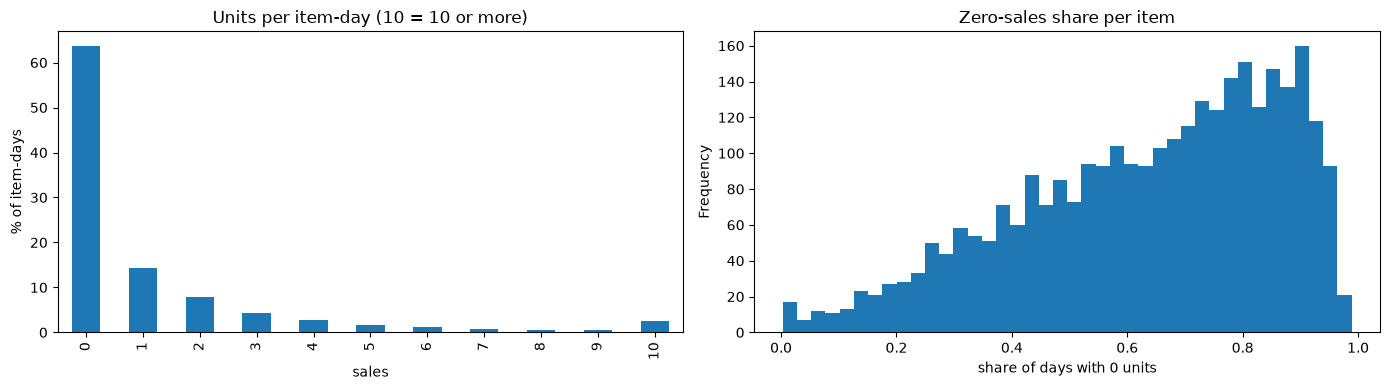

In [7]:
# Cell 3: Distribution of sales and zero share per item

# Distribution of units per item-day (cap at 10+)
capped = df["sales"].clip(upper=10)
dist = capped.value_counts(normalize=True).sort_index()
display((dist * 100).round(1).rename("share_%").to_frame())

# zero share per item
zero_by_item = (df["sales"] == 0).groupby(df["item_id"], observed=True).mean()
print("items with zero share > 90%:", (zero_by_item > 0.9).sum())
print("items with zero share < 30%:", (zero_by_item < 0.3).sum())
print(zero_by_item.describe().round(3))

fig, ax = plt.subplots(1, 2, figsize = (14, 4))
dist.mul(100).plot(kind="bar", ax=ax[0])
ax[0].set_title("Units per item-day (10 = 10 or more)")
ax[0].set_ylabel("% of item-days")

zero_by_item.plot(kind="hist", bins = 40, ax = ax[1])
ax[1].set_title("Zero-sales share per item")
ax[1].set_xlabel("share of days with 0 units")
plt.tight_layout()
plt.show()

### **What the two charts say**
- Most item-days are zero. 63.8% are 0, 14.3% are 1 and 7.8% are 2, so about 86% of all item-days are 0, 1 or 2 units. Only 2.5% reach 10 or more.
- Items differ a lot in how often they sell. The median item has no sales on 68% of days. 329 items are zero on more than 90% of days, and 288 items are zero on less than 30% of days. The histogram has a long tail toward 1.0, so a large group of items sells rarely and is close to unpredictable.

### **What this means for the model:**

- MAPE is unusable here, because a zero actual makes the percentage undefined or infinite. We stay with MAE, WAPE and MASE.
- An item that is zero 90% of the time has a forecast of about 0.1 units/day. Item-level errors will look large in relative terms, while the store total is much easier to predict. That is the hierarchy point for your README.
- For a model with squared error, most rows are 0 and a few are large, so we’ll consider a count-friendly objective (for example Poisson or Tweedie in LightGBM) when we reach Notebook 06.

items with a price at some point: 3049 of 3049
on sale from day 1              : 1204
first price after day 1500      : 28
items whose price ends before the last day: 0
items with gaps in the price histroy      : 0

zero share while on sale (per item):
count    3049.000
mean        0.558
std         0.227
min         0.003
25%         0.392
50%         0.580
75%         0.745
max         0.972
Name: zero_share_on_sale, dtype: float64


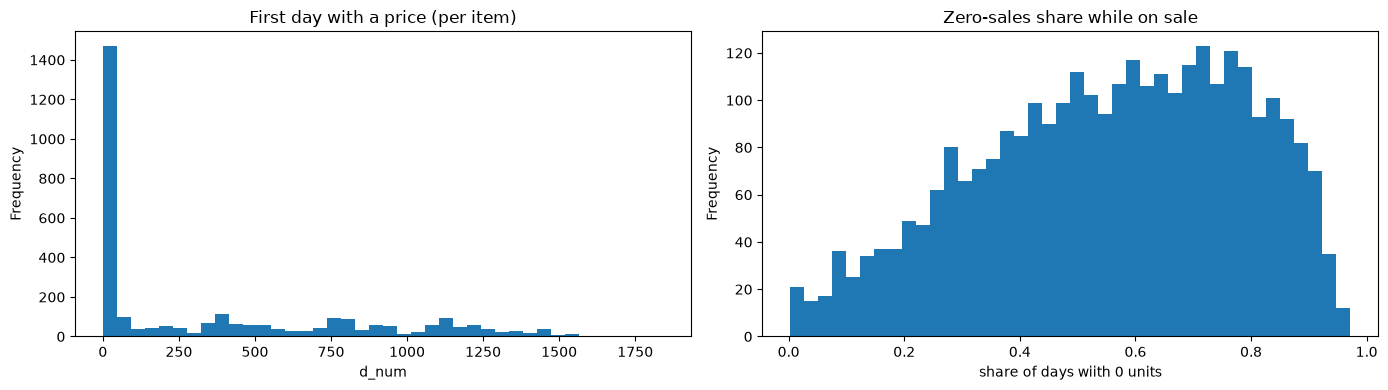

In [10]:
# Cell 4: How long has each item been on sale?
on_sale = df[df["sell_price"].notna()]

first_day = on_sale.groupby("item_id", observed=True)["d_num"].min().rename("first_day")
last_day = on_sale.groupby("item_id", observed=True)["d_num"].max().rename("last_day")
days_on_sale = on_sale.groupby("item_id", observed=True).size().rename("days_on_sale")
zero_on_sale = ((on_sale["sales"] == 0).groupby(on_sale["item_id"], observed=True)
                .mean().rename("zero_share_on_sale"))
items = pd.concat([first_day, last_day, days_on_sale, zero_on_sale], axis= 1)
items["span"] = items["last_day"] - items["first_day"] + 1
items["gap_days"] = items["span"] - items["days_on_sale"]

print("items with a price at some point:", len(items), "of", df["item_id"].nunique())
print("on sale from day 1              :", (items["first_day"] == 1).sum())
print("first price after day 1500      :", (items["first_day"] > 1500).sum())
print("items whose price ends before the last day:", (items["last_day"] < 1941).sum())
print("items with gaps in the price histroy      :", (items["gap_days"] > 0).sum())
print("\nzero share while on sale (per item):")
print(items["zero_share_on_sale"].describe().round(3))

fig, ax = plt.subplots(1, 2, figsize = (14, 4))
items["first_day"].plot(kind="hist", bins = 40, ax=ax[0])
ax[0].set_title("First day with a price (per item)")
ax[0].set_xlabel("d_num")
items["zero_share_on_sale"].plot(kind="hist", bins = 40, ax = ax[1])
ax[1].set_title("Zero-sales share while on sale")
ax[1].set_xlabel("share of days wiith 0 units")
plt.tight_layout()
plt.show()

### **What the output says**
- Every price gap is a late launch. All 3,049 items have a price at some point, none stops before the last day, and none has gaps in its price history. So the 19.1% missing prices are all before the item launched, never mid-life.
- About 40% of items were on sale from day 1 (1,204 of 3,049). The rest launched later, and 28 launched after day 1500. The first histogram bar looks like roughly 1,470 items, which means about 270 more launched in the first weeks.
- The zero problem is a bit smaller than it looked. While on sale, the median item’s zero share is 0.580, down from 0.681 over all days, and the mean is 0.558, down from 0.638. Still, over half of on-sale item-days are zero for the typical item, so intermittent demand is real. The right chart still reaches 0.97, so a group of items is close to unforecastable.
- One thing we can’t separate: a zero while the item has a price can mean no demand or an empty shelf (a stockout). The data doesn’t tell us which, so your README should say that “demand” here means observed sales.

### **What this means for the model:**

- Rows before an item’s first price should not be used for training or for computing metrics. The item did not exist yet, so a forecast of 0 there would look like a perfect score.
- We keep those rows in the parquet and exclude them when we build the training table, using sell_price.notna() or a first_day per item. That choice will go into src/ later. If you’d rather drop them in the parquet itself, tell me and we discuss it, but I’d keep the full table so the raw reshape stays reproducible.
- Items that launched late have short histories, so lag features of 28 days or more will be missing for their first weeks. We check how many in Notebook 05.

## **Bivariate Analysis**

,mean,median,std,index_vs_avg
weekday,,,,
Monday,3865.0,3938.0,649.0,0.955
Tuesday,3433.0,3488.0,561.0,0.849
Wednesday,3342.0,3418.0,565.0,0.826
Thursday,3380.0,3432.0,569.0,0.836
Friday,4047.0,4112.0,613.0,1.000
Saturday,5078.0,5165.0,733.0,1.255
Sunday,5163.0,5291.0,837.0,1.276


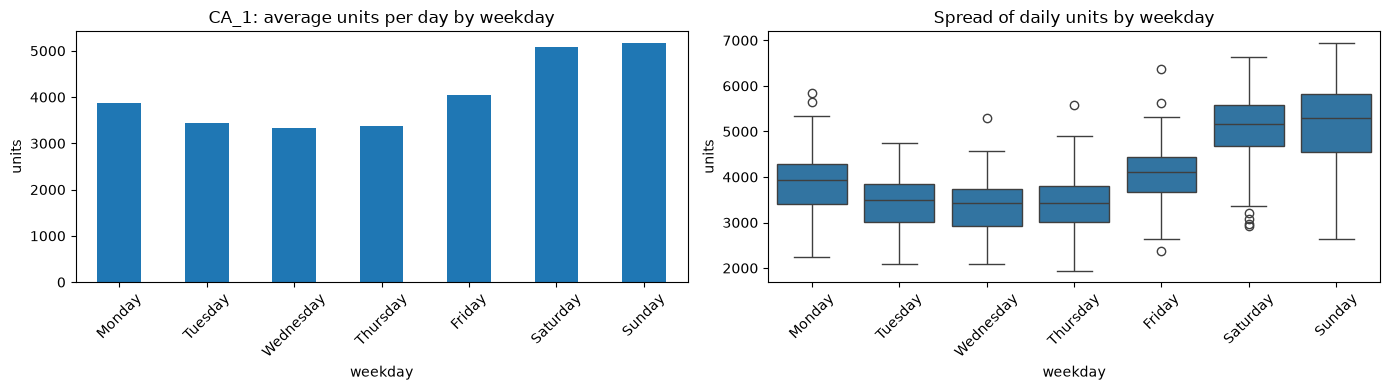

In [14]:
# Cell 5: Weekly pattern (sales vs weekday)
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

# Store total per day, without 25 December (store closed)
d = daily[["units"]].copy()
d = d[~((d.index.month == 12) & (d.index.day == 25))]
d["weekday"] = d.index.day_name()

by_wd = d.groupby("weekday")["units"].agg(["mean", "median", "std"]).reindex(order)
by_wd["index_vs_avg"] = by_wd["mean"] / d["units"].mean()
display(by_wd.round({"mean": 0, "median": 0, "std": 0, "index_vs_avg": 3}))

fig, ax = plt.subplots(1, 2, figsize = (14, 4))
by_wd["mean"].plot(kind = "bar", ax = ax[0])
ax[0].set_title("CA_1: average units per day by weekday")
ax[0].set_ylabel("units")
sns.boxplot(data = d, x ="weekday", y = "units", order = order, ax = ax[1])
ax[1].set_title("Spread of daily units by weekday")
for a in ax:
    a.tick_params(axis = "x", rotation = 45)
plt.tight_layout()
plt.show()

### **What the table says:**
- Weekends are the peak. Sunday (5,163) and Saturday (5,078) are about 28% and 26% above average, and the spread is widest on Sunday (std 837).
- Tuesday and Wednesday are the lowest (about 15% and 17% below average). Monday sits just under average, and Friday is average (1.000).
- Weekdays barely overlap with weekends. In the boxplot, Saturday and Sunday boxes sit clearly above Tuesday and Wednesday, so weekday is a strong feature for the model.
- Thursday is still unknown. Don’t read anything into it until the cell is re-run. Paste the full table, and then I can say where it falls.

,index_vs_year_avg
month,
1,0.900
2,0.941
3,0.965
4,0.999
5,1.007
6,1.061
7,1.057
8,1.093
9,1.047


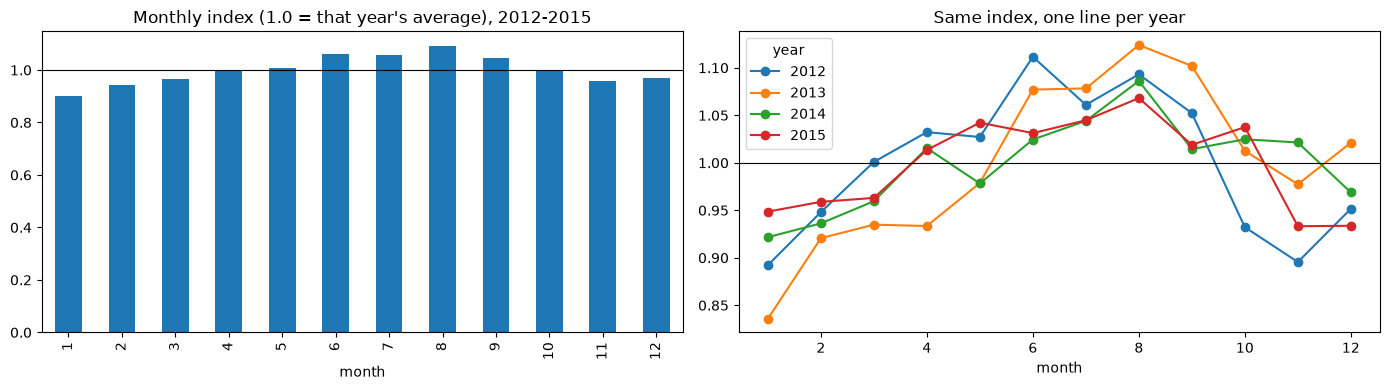

In [19]:
# Cell 6: Yearly pattern (sales vs month)
m = daily[["units"]].copy()
m = m[~((m.index.month == 12) & (m.index.day == 25))]
m["year"] = m.index.year
m["month"] = m.index.month

m = m[m["year"].between(2012, 2015)]          # full years only
m["rel"] = m["units"] / m.groupby("year")["units"].transform("mean")

month_idx = m.groupby("month")["rel"].mean().rename("index_vs_year_avg")
display(month_idx.round(3).to_frame())

pivot = m.pivot_table(index="month", columns="year", values="rel", aggfunc="mean")

fig, ax = plt.subplots(1, 2, figsize = (14, 4))
ax[0].axhline(1, color = "k", lw = 0.8)
month_idx.plot(kind = "bar", ax = ax[0])
ax[0].set_title("Monthly index (1.0 = that year's average), 2012-2015")
ax[0].set_xlabel("month")
pivot.plot(ax = ax[1], marker = "o")
ax[1].axhline(1, color = "k", lw = 0.8)
ax[1].set_title("Same index, one line per year")
ax[1].set_xlabel("month")
plt.tight_layout()
plt.show()

### **What the four lines say**
- January is the lowest or near-lowest month in all four years (roughly 0.84 to 0.95).
- Every year rises into summer and peaks around June to August. August is the high point in 2013, 2014 and 2015 (about 1.07 to 1.12), and in 2012 June is slightly higher than August.
- The shape is consistent, the size is not. In 2013 the swing is large (about 0.84 to 1.12). In 2015 it is much flatter (about 0.93 to 1.07).
- Autumn and winter are less reliable. From October to December the lines split. 2012 drops to about 0.90 in November, while 2014 stays above 1.0 until November. A “November is low” rule would hold for three of the four years, not all four.
- The growth caveat applies. 2012 and 2013 were growth years for the store (Cell 2), which makes their Januaries look lower than seasonality alone would. 2015 is the flattest year, which fits the plateau you saw in the red line.

,count,mean
event_type_1,,
Cultural,37,0.891
Sporting,16,0.974
none,1783,1.004
Religious,54,1.012
National,46,1.030


lowest 8 events:


,count,mean
event_name_1,,
Thanksgiving,5,0.697
NewYear,5,0.796
Easter,5,0.808
Father's day,4,0.839
Mother's day,6,0.841
Halloween,5,0.886
ValentinesDay,6,0.892
StPatricksDay,6,0.927


highest 8 events:


,count,mean
event_name_1,,
Cinco De Mayo,5,1.039
MemorialDay,5,1.043
OrthodoxChristmas,5,1.072
VeteransDay,5,1.077
PresidentsDay,6,1.086
MartinLutherKingDay,5,1.097
ColumbusDay,5,1.116
LaborDay,5,1.354


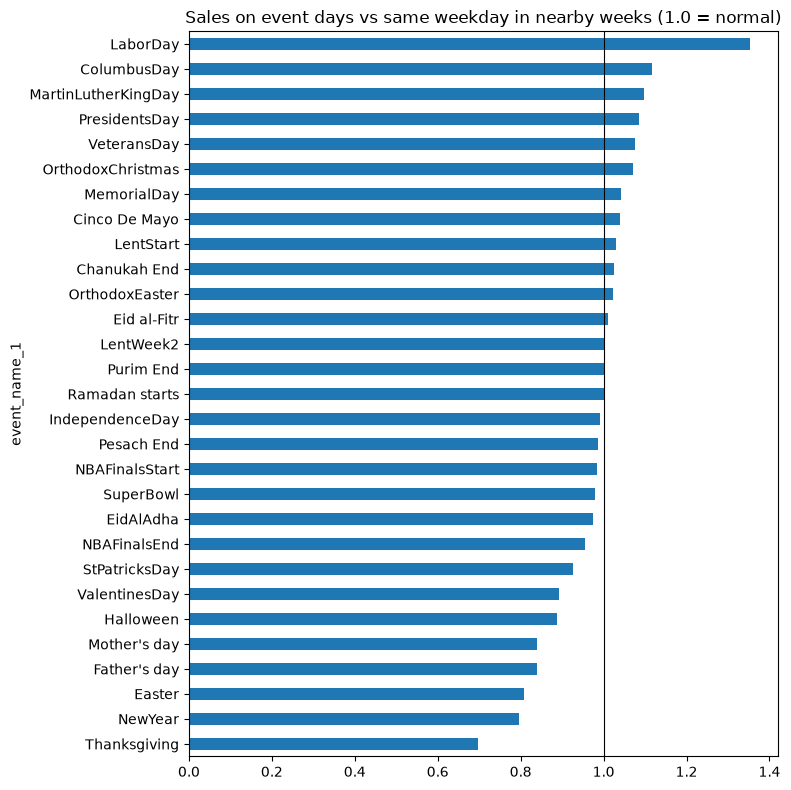

In [21]:
# Cell 7: Events and holidays (sales vs event)
s = daily["units"].astype(float).copy()
s[(s.index.month == 12) & (s.index.day == 25)] = np.nan      # store closed

neighbors = pd.concat([s.shift(k) for k in (7, 14, -7, -14)], axis=1)
ev = pd.DataFrame({"units": s, "base": neighbors.mean(axis=1)})
ev["rel"] = ev["units"] / ev["base"]

cal_info = (df.drop_duplicates("date").set_index("date")[["event_name_1", "event_type_1"]])
ev = ev.join(cal_info)
for c in ["event_name_1", "event_type_1"]:
    ev[c] = ev[c].astype(object).fillna("none")
ev = ev.dropna(subset=["rel"])

by_type = ev.groupby("event_type_1")["rel"].agg(["count", "mean"]).sort_values("mean")
display(by_type.round(3))

by_name = (ev[ev["event_name_1"] != "none"].groupby("event_name_1")["rel"].agg
           (["count", "mean"]).sort_values("mean"))

print("lowest 8 events:")
display(by_name.head(8).round(3))
print("highest 8 events:")
display(by_name.tail(8).round(3))

fig, ax = plt.subplots(figsize = (8, 8))
by_name["mean"].plot(kind = "barh", ax = ax)
ax.axvline(1, color="k", lw = 0.8)
ax.set_title("Sales on event days vs same weekday in nearby weeks (1.0 = normal)")
plt.tight_layout()
plt.show()

### **What the event table says**
- The baseline works. Days with no event have a ratio of 1.004, so the method is unbiased and the event rows can be trusted as a comparison.
- Event types hide opposite effects. Cultural events average 0.891 and National 1.030, but inside a type the events go in both directions. You can see this in the chart: Thanksgiving (0.697) and Labor Day (1.354) are the two extremes, and both are US holidays. So the model should get the event name as a feature, not only the type.
- The big drops are the family and food holidays. Thanksgiving (about 30% below normal), NewYear (20% below), Easter, Father’s Day and Mother’s Day (16 to 19% below). Easter and the two parent days fall on Sundays, the store’s busiest weekday, so the drop is against a high baseline.
- Long weekends are mostly up. Labor Day (1.354) is the extreme, and Columbus Day, MLK Day, Presidents Day and Veterans Day are all 8 to 12% above normal. Those holidays fall on a Monday (Veterans Day moves around), and the store sells more on them than on a normal Monday.
- Religious and sporting events change little. Eid, Ramadan, Lent, Super Bowl and the NBA finals all sit within about 5% of 1.0.
- Sample size is small. Every event has only 4 to 6 observations, so ranking events within a few percent of each other (say, 1.03 against 1.04) means nothing. Only the large gaps (Thanksgiving, NewYear, Easter, parent days, Labor Day) are strong enough to rely on.
- The store-level effect hides items. Events fall on about 8% of days (about 150 of 1,941), so their effect on the total is limited. A single item, such as one that sells for Thanksgiving dinner, may react much more. That is a guess, and we can test it later with SHAP or a per-item check.

SNAP days share: 0.33
days of month with SNAP = 1: [np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6), np.int32(7), np.int32(8), np.int32(9), np.int32(10)]


C:\Users\ASUS\AppData\Local\Temp\ipykernel_2964\1073115298.py:18: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  res = cd.pivot_table(index="cat_id", columns="snap", values="rel", aggfunc="mean")


snap,0,1,snap_vs_no_snap
cat_id,,,
FOODS,0.963,1.075,1.117
HOBBIES,0.988,1.025,1.038
HOUSEHOLD,0.985,1.030,1.046


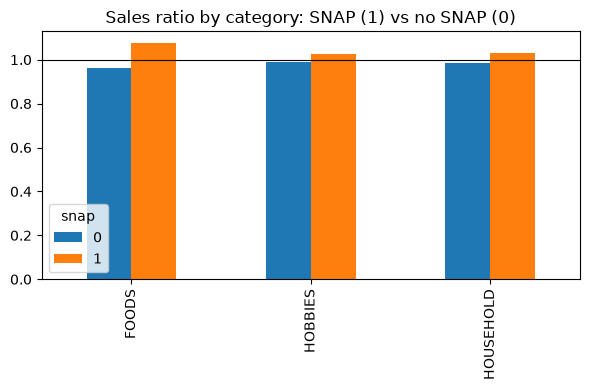

In [22]:
# Cell 8: SNAP days (sales vs SNAP)
# how many days have SNAP, and when in the month
snap_day = df.drop_duplicates("date")[["date", "snap"]].copy()
snap_day["dom"] = snap_day["date"].dt.day
print("SNAP days share:", round(snap_day["snap"].mean(), 3))
print("days of month with SNAP = 1:", sorted(snap_day.loc[snap_day["snap"] == 1, "dom"].unique()))

# store sales per category per day (store-closed 25 Dec removed)
d2 = df[~((df["date"].dt.month == 12) & (df["date"].dt.day == 25))]
cd = d2.groupby(["date", "cat_id"], observed=True)["sales"].sum().reset_index()
cd = cd.merge(snap_day[["date", "snap"]], on="date")
cd["wday"] = cd["date"].dt.dayofweek
cd["ym"] = cd["date"].dt.to_period("M")

# ratio to the same category + weekday + year-month average
cd["rel"] = cd["sales"] / cd.groupby(["cat_id", "wday", "ym"], observed=True)["sales"].transform("mean")

res = cd.pivot_table(index="cat_id", columns="snap", values="rel", aggfunc="mean")
res["snap_vs_no_snap"] = res[1] / res[0]
display(res.round(3))

fig, ax = plt.subplots(figsize = (6, 4))
res[[0, 1]].plot(kind = "bar", ax = ax)
ax.axhline(1, color = "k", lw= 0.8)
ax.set_title("Sales ratio by category: SNAP (1) vs no SNAP (0)")
ax.set_xlabel("")
plt.tight_layout()
plt.show()

### **What the SNAP result says**
- SNAP covers days 1 to 10 of each month, which is 33% of days.
- FOODS sells about 12% more on SNAP days (ratio 1.117). That is the biggest gap, and it matches what you would expect from a food-assistance program.
- HOBBIES (+3.8%) and HOUSEHOLD (+4.6%) also rise. SNAP can’t explain this, because it applies to food only. This is the caveat I mentioned: days 1 to 10 are also the start of the month, when people get paid, so part of the FOODS lift is probably a general “early month” effect and not SNAP. If you take the non-food lift (about 4%) as the early-month baseline, the extra FOODS lift is about 7 to 8 points. That is my rough reading, and this data can’t separate the two properly.
### **Why the blue bars sit below 1.0:**
- the ratio is “versus the average of the same category, weekday and month”, and SNAP days pull that average up, so non-SNAP days land a little under 1.

### **For the model:**
- keep snap as a feature (it is cheap and the FOODS signal is real). Day of month could be a useful extra feature, since it captures the paycheck pattern that SNAP overlaps with. SHAP in Notebook 08 will show how much each matters.

C:\Users\ASUS\AppData\Local\Temp\ipykernel_2964\301082352.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  x["price_ratio"] = x["sell_price"] / x["med_price"]
C:\Users\ASUS\AppData\Local\Temp\ipykernel_2964\301082352.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  x["sales_ratio"] = x["sales"] / x["item_mean"]
C:\Users\ASUS\AppData\Local\Temp\ipykernel_2964\301082352.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_ind

,rows,items,sales_ratio
price_bin,,,
<0.80,18966,161,1.441
0.80-0.90,98726,451,1.308
0.90-0.97,230501,684,1.163
0.97-1.03,2495810,2013,0.988
1.03-1.10,231602,600,0.900
1.10-1.25,112938,321,0.803
>1.25,7278,36,0.772


items kept: 2013
share of rows within 3% of the item's median price: 0.781


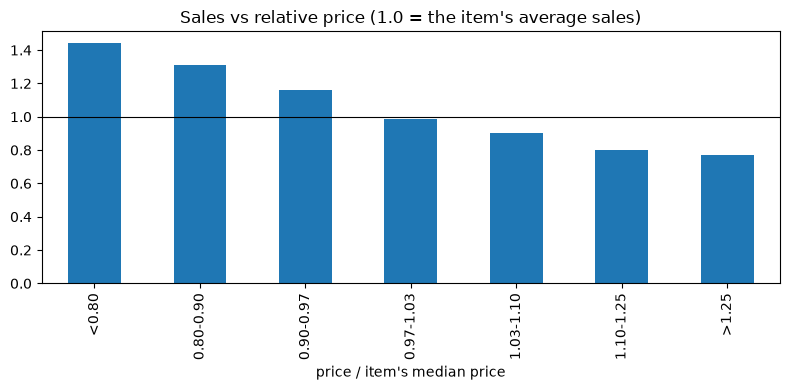

In [23]:
# Cell 9: Price effects (sales vs price)

x = df.loc[df["sell_price"].notna(), ["item_id", "date", "sales", "sell_price"]].copy()
x = x[~((x["date"].dt.month == 12) & (x["date"].dt.day == 25))]            # sorted closed

g = x.groupby("item_id", observed=True)
x["med_price"] = g["sell_price"].transform("median")
x["item_mean"] = g["sales"].transform("mean")
x = x[x["item_mean"] >= 0.5]

x["price_ratio"] = x["sell_price"] / x["med_price"]
x["sales_ratio"] = x["sales"] / x["item_mean"]

bins = [0, 0.8, 0.9, 0.97, 1.03, 1.1, 1.25, 10]
labels = ["<0.80", "0.80-0.90", "0.90-0.97", "0.97-1.03", "1.03-1.10", "1.10-1.25", ">1.25"]
x["price_bin"] = pd.cut(x["price_ratio"], bins= bins, labels=labels)

res = x.groupby("price_bin", observed=True).agg(
    rows = ("sales_ratio", "size"),
    items = ("item_id", "nunique"),
    sales_ratio = ("sales_ratio", "mean"),
)
display(res.round(3))

print("items kept:", x["item_id"].nunique())
print("share of rows within 3% of the item's median price:",
      round(x["price_ratio"].between(0.97, 1.03).mean(), 3))

fig, ax = plt.subplots(figsize = (8, 4))
res["sales_ratio"].plot(kind = "bar", ax = ax)
ax.axhline(1, color = "k", lw = 0.8)
ax.set_title("Sales vs relative price (1.0 = the item's average sales)")
ax.set_xlabel("price / item's median price")
plt.tight_layout()
plt.show()

### **What the price result says**
- Price carries a strong signal. Sales fall steadily as the relative price rises. Items sell about 44% above their own average when priced under 0.80 of their median price (ratio 1.441), about average near the median (0.988), and about 23% below when priced above 1.25 of it (0.772). The pattern never reverses, which is what you’d expect from price sensitivity.
- The change is rare. 78.1% of rows sit within 3% of the item’s median price, and the rest split into roughly 11% below and 11% above (my arithmetic from your row counts). So price matters a lot when it moves, but it moves for only about one row in five, and sell_price as a raw feature will be much weaker than a relative price feature (price versus the item’s recent price).
- Treat the extreme bins with care. <0.80 has 161 items and >1.25 has 36 items, so those two bars rest on small groups. The middle bins (hundreds of items, 100k+ rows) are solid.
- Only 2,013 of the 3,049 items are in this table, because the others sell under 0.5 units a day on average. For those slow items the price effect is simply not measurable this way.
- Correlation, not proof. Discounts often come with events or the season (Labor Day went up 35% in Cell 7). Also, the price scale inside an item can drift upward over the years while sales trend too. So read this as “price is informative”, not “a 10% discount gives 16% more sales”.

### **For the model:**
- use price features based on change: price / price 7 days ago, price / item's rolling median (shifted so no future prices leak, although the model may use current price because the price is known in advance). Build these in Notebook 05. Raw sell_price can stay, but the ratio features will do most of the work.

### **Multivariate Analysis**

weekday,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
cat_id,,,,,,,
FOODS,0.956,0.845,0.824,0.834,1.003,1.250,1.287
HOBBIES,0.944,0.896,0.885,0.887,1.034,1.247,1.109
HOUSEHOLD,0.965,0.834,0.800,0.810,0.971,1.281,1.339


C:\Users\ASUS\AppData\Local\Temp\ipykernel_2964\2990578624.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  x["cat_id"] = x["item_id"].astype(str).map(cat_of)


cat_id,FOODS,HOBBIES,HOUSEHOLD
price_bin,,,
<0.80,1.464,0.245,1.300
0.80-0.90,1.349,1.152,1.282
0.90-0.97,1.175,1.134,1.155
0.97-1.03,0.985,0.988,0.995
1.03-1.10,0.910,0.811,0.926
1.10-1.25,0.776,1.156,0.831
>1.25,0.758,NaN,0.860


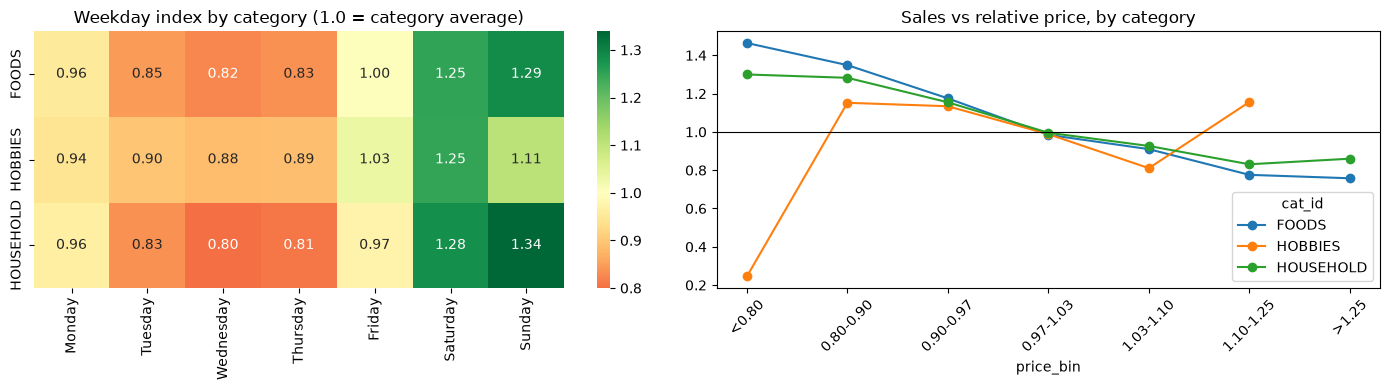

In [26]:
# Cell 10: weekday x category, and price x category

days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

# a) weekday pattern by category
d3 = df[~((df["date"].dt.month == 12) & (df["date"].dt.day == 25))]
cw = d3.groupby(["date", "cat_id"], observed=True)["sales"].sum().reset_index()
cw["weekday"] = cw["date"].dt.day_name()
heat = cw.pivot_table(index="cat_id", columns="weekday", values="sales",
                      aggfunc="mean", observed=True)[days]
heat = heat.div(heat.mean(axis = 1), axis=0)
display(heat.round(3))

# b) price sensitivity by category
cat_of = dict(zip(df["item_id"].astype(str), df["cat_id"].astype(str)))
x["cat_id"] = x["item_id"].astype(str).map(cat_of)
pb = x.pivot_table(index="price_bin", columns="cat_id", values="sales_ratio",
                   aggfunc="mean", observed=True)

display(pb.round(3))

fig, ax = plt.subplots(1, 2, figsize = (14, 4))
sns.heatmap(heat, annot = True, fmt = ".2f", cmap="RdYlGn", center = 1, ax = ax[0])
ax[0].set_title("Weekday index by category (1.0 = category average)")
ax[0].set_xlabel("")
ax[0].set_ylabel("")
pb.plot(marker = "o", ax=ax[1])
ax[1].axhline(1, color = "k", lw = 0.8)
ax[1].set_title("Sales vs relative price, by category")
ax[1].tick_params(axis = "x", rotation = 45)
plt.tight_layout()
plt.show()

### **Panel A: weekday pattern by category**
- All three categories share one weekly shape. Tuesday to Thursday are low (about 0.80 to 0.90), Friday is near average, and Saturday and Sunday are the peaks (1.11 to 1.34). So a single weekday feature is justified for all items.
- The size of the swing differs. HOUSEHOLD has the sharpest cycle: Sunday 1.34, Wednesday 0.80, a 54-point gap. FOODS is close behind (1.29 to 0.82). - HOBBIES is the flattest: its low is only 0.88 and its Sunday is just 1.11.
- HOBBIES peaks on Saturday (1.25), not Sunday (1.11). FOODS and HOUSEHOLD peak on Sunday. That is a real difference, and it is why the model needs cat_id or dept_id next to the weekday. LightGBM learns that kind of interaction on its own.
- Thursday is no longer blank because this cell used the correct spelling. It sits with Tuesday and Wednesday in every category (0.81 to 0.89). The store-level Thursday will most likely land in the same range.

### **Panel B: price sensitivity by category**
- FOODS and HOUSEHOLD behave alike. Sales fall steadily as the relative price rises. FOODS is a little steeper (1.46 at under 0.80, 0.76 above 1.25) than HOUSEHOLD (1.30 and 0.86), so food items react a bit more to price. Both lines cross 1.0 at the normal price, as they should.
- HOBBIES is erratic, and I wouldn’t read anything into it yet. It shows 0.245 in the cheapest bin, then 1.15, then 1.16 in the 1.10 to 1.25 bin, and no data above 1.25. A line that jumps like that usually means a handful of items or rows in those bins. In the middle bins (0.90 to 1.10) HOBBIES matches the others. I can’t tell from this table how thin the extreme bins are, so check before concluding that HOBBIES doesn’t respond to price.

In [27]:
# Cell 11: 
cnt = x.pivot_table(index="price_bin", columns="cat_id", values="item_id",
                    aggfunc=["size", "nunique"], observed=True)
display(cnt)

size                     nunique                  
cat_id         FOODS   HOBBIES HOUSEHOLD   FOODS HOBBIES HOUSEHOLD
price_bin                                                         
<0.80        17221.0     154.0    1591.0   130.0     4.0      27.0
0.80-0.90    69461.0   15600.0   13665.0   320.0    75.0      56.0
0.90-0.97   142715.0   47429.0   40357.0   440.0   114.0     130.0
0.97-1.03  1470095.0  308011.0  717704.0  1217.0   252.0     544.0
1.03-1.10   155567.0   30121.0   45914.0   408.0    74.0     118.0
1.10-1.25    85554.0    4859.0   22525.0   253.0    14.0      54.0
>1.25         6236.0       NaN    1042.0    32.0     NaN       4.0

### **What the counts say**

- The odd HOBBIES pattern comes from thin bins, as I suspected:

- <0.80: only 154 rows from 4 items. The 0.245 is noise.
- 1.10-1.25: 4,859 rows from 14 items. Too thin to trust the 1.156.
- >1.25: no HOBBIES rows at all, which is why the line stops.
- Solid bins (0.80 to 1.10): 15k to 300k rows from 74 to 252 items. There HOBBIES follows the same shape as the other categories (1.15, 1.13, 0.99, then 0.81). The 0.81 in the 1.03-1.10 bin is lower than the others (0.91 and 0.93), so HOBBIES may be slightly more price-sensitive on the upside, but one bin isn’t enough to say so.

### **Conclusion:**
- HOBBIES has very few big price changes, so we can’t estimate how it reacts to them. In your README, write “price effect measured mainly for FOODS and HOUSEHOLD”. The model can still use price features for all categories.

## Summary of Notebook 02: EDA

| Finding | Evidence | What it means for modelling |
|---|---|---|
| Store sales grew 2011-2013, then flattened | 28-day mean rose from about 3,000 to about 4,700 units/day, then stayed between 4,000 and 4,800 | Series is not stationary; use lags of 28+ days and do not assume a constant level |
| Store closed on 25 December | 0 units every year (2011-2015) | Add a Christmas flag; do not learn those zeros as demand; careful with backtest folds |
| Demand is intermittent | 63.8% of item-days are 0 (55.2% while on sale); median item is zero 68% of days | No MAPE; use MAE, WAPE, MASE; consider Poisson/Tweedie objective |
| Late-launched items | All 19.1% missing prices are before launch; no gaps, no delistings; 1,204 items on sale from day 1 | Exclude pre-launch rows from training and metrics; short histories give missing lags |
| Strong weekday pattern | Tuesday-Thursday about 0.83-0.85, Saturday 1.255, Sunday 1.276 (store index) | `weekday` is the strongest calendar feature |
| Weekday shape by category | Same shape in all three; HOUSEHOLD swings most; HOBBIES peaks Saturday, others Sunday | Give the model `cat_id`/`dept_id` so it learns the interaction |
| Moderate yearly seasonality | Low in January, high in June-August in all four full years; amplitude varies | `month` / day of year as features (effect about ±10%) |
| Events matter by name, not type | Thanksgiving 0.70, NewYear 0.80, Easter 0.81, Labor Day 1.35; no-event baseline 1.004; 4-6 observations per event | Use `event_name_1` and `event_type_1`; treat small differences as noise |
| SNAP lifts food sales | FOODS +11.7% on SNAP days, others +4-5%; SNAP is days 1-10 | Keep `snap`; add day-of-month because the paycheck effect overlaps |
| Price carries signal | Sales ratio 1.44 below 0.80 of median price, 0.77 above 1.25; 78% of rows near the median | Use relative price features (price vs item's recent price), not only raw price |
| Price effect by category | FOODS and HOUSEHOLD similar; HOBBIES has too few price changes to estimate | Say so in the README |

**Leakage rules**
- Event ratios in this notebook use future days, so they are for EDA only and never become features.
- Rolling features must be shifted.

**Corrections for the README**
- Sales data covers 2011-01-29 to 2016-05-22 (1,941 days), not to 2016-06-19.
- Zero sales while an item has a price can mean no demand or an empty shelf; "demand" here means observed sales.